In [ ]:
# !pip install catboost

In [ ]:
# !pip install lightgbm

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.figsize'] = (8, 5)

import warnings
warnings.filterwarnings('ignore')

# Boostings

Данные с которыми вы будете работать представляют из себя характеристики клиента страховой компании по которым нужно понять будет ли он заинтересован в страховке. Таким образом, страховая компания может более оптимально таргетить рекламу и выстраивать коммуникацию с клиентами, повышая конверсию.

**Описания колонок:**
- Gender - Male, Female
- Age - Возраст
- Driving_License - Наличие водительского удостоверения
- Region_Code - Область проживания
- Previously_Insured - Пользовался ли раньше услугами страховой компании
- Vehicle_Age - Возраст транспортного средства
- Vehicle_Damage - Попадало ли траспортное средство в ДТП
- Annual_Premium - Ежегодные выплаты клиента
- Policy_Sales_Channel - Политика распространения страховых услуг (через посредников, напрямую и т.д.)
- Vintage - Количество дней, в течение которых клиент был связан с компанией 


- **Response** - заинтересован в страховке 1, не откликнулся 0

In [18]:
data = pd.read_csv('vehicle_insurance.csv')

data[data['Driving_License']==0].head(22)

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
563,Male,69,0,33.0,0,1-2 Year,Yes,39730.0,26.0,53,0
1061,Male,71,0,3.0,0,1-2 Year,No,25323.0,26.0,179,0
1761,Female,58,0,28.0,0,1-2 Year,Yes,53047.0,122.0,214,0
1990,Male,66,0,8.0,0,1-2 Year,No,48063.0,25.0,231,0
2365,Female,52,0,45.0,1,1-2 Year,No,33283.0,26.0,152,0
2698,Male,67,0,1.0,1,1-2 Year,No,2630.0,26.0,35,0
2943,Male,67,0,8.0,0,1-2 Year,Yes,45024.0,7.0,124,0
2957,Male,72,0,28.0,0,1-2 Year,Yes,72033.0,26.0,253,0
3142,Male,61,0,41.0,0,1-2 Year,Yes,40121.0,26.0,21,0
3182,Male,78,0,48.0,1,1-2 Year,Yes,2630.0,124.0,157,0


**Задание 0.** Проведите небольшой EDA. Посмотрите на распределения некоторых колонок, на матрицу корреляций. Также проверьте баланс классов и посмотрите на распределение возраста транспортного средства в зависимости от response. \
Закодируйте признаки типа `object` с помощью `one-hot` кодирования.

P.S. некоторые не `object`колонки по смыслу очевидно являются категориальными. Так как мы будем строить ансамбли на основе деревьев, их можно оставить в первоначальном виде.

In [15]:
data.describe()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,38.812900,0.997800,26.425400,0.443800,30609.649700,112.414400,155.560300,0.124700
std,15.514785,0.046855,13.153552,0.496856,16562.392967,53.975042,83.923849,0.330395
min,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,25.000000,1.000000,15.000000,0.000000,24458.250000,30.000000,83.000000,0.000000
50%,36.000000,1.000000,28.000000,0.000000,31746.000000,136.000000,156.000000,0.000000
75%,49.000000,1.000000,35.000000,1.000000,39572.250000,152.000000,228.000000,0.000000
max,84.000000,1.000000,52.000000,1.000000,267698.000000,163.000000,299.000000,1.000000


Баланс классов в целевой переменной 'Response':
Response
0    0.8753
1    0.1247
Name: proportion, dtype: float64


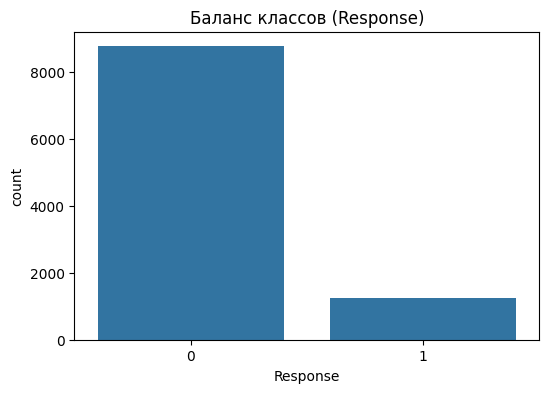

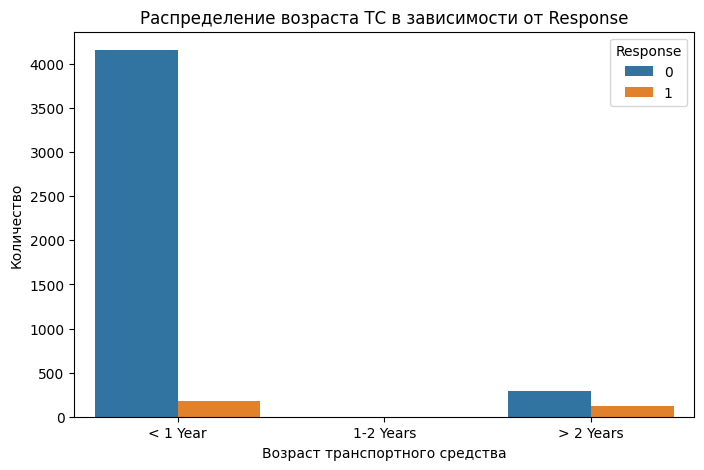

Колонки типа object, которые будут закодированы: ['Gender', 'Vehicle_Age', 'Vehicle_Damage']

Новая форма датасета после One-Hot кодирования: (10000, 12)


,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response,Gender_Male,Vehicle_Age_< 1 Year,Vehicle_Age_> 2 Years,Vehicle_Damage_Yes
0,44,1,28.0,0,40454.0,26.0,217,1,1,0,1,1
1,76,1,3.0,0,33536.0,26.0,183,0,1,0,0,0
2,47,1,28.0,0,38294.0,26.0,27,1,1,0,1,1
3,21,1,11.0,1,28619.0,152.0,203,0,1,1,0,0
4,29,1,41.0,1,27496.0,152.0,39,0,0,1,0,0


In [13]:
# ==========================================
# 1. ПРОВЕРКА БАЛАНСА КЛАССОВ
# ==========================================
print("Баланс классов в целевой переменной 'Response':")
print(data['Response'].value_counts(normalize=True)) # Покажет доли классов в процентах

plt.figure(figsize=(6, 4))
sns.countplot(x='Response', data=data)
plt.title('Баланс классов (Response)')
plt.show()

# ==========================================
# 2. РАСПРЕДЕЛЕНИЕ ВОЗРАСТА МАШИНЫ В ЗАВИСИМОСТИ ОТ RESPONSE
# ==========================================
plt.figure(figsize=(8, 5))
# Строим упорядоченный график, чтобы категории шли красиво: < 1 Year, 1-2 Years, > 2 Years
age_order = ['< 1 Year', '1-2 Years', '> 2 Years']
sns.countplot(x='Vehicle_Age', hue='Response', data=data, order=age_order)
plt.title('Распределение возраста ТС в зависимости от Response')
plt.xlabel('Возраст транспортного средства')
plt.ylabel('Количество')
plt.show()

# ==========================================
# 3. ONE-HOT КОДИРОВАНИЕ ПРИЗНАКОВ ТИПА OBJECT
# ==========================================
# Находим все колонки с типом данных object
object_cols = data.select_dtypes(include=['object']).columns.tolist()
print(f"Колонки типа object, которые будут закодированы: {object_cols}")

# Применяем One-Hot Encoding через pd.get_dummies
# drop_first=True удаляет одну из колонок-дубликатов для избежания мультиколлинеарности
data_encoded = pd.get_dummies(data, columns=object_cols, drop_first=True)

# Переводим булевые значения True/False в числа 1/0
for col in data_encoded.columns:
    if data_encoded[col].dtype == 'bool':
        data_encoded[col] = data_encoded[col].astype(int)

# Проверяем результат
print(f"\nНовая форма датасета после One-Hot кодирования: {data_encoded.shape}")
data_encoded.head()

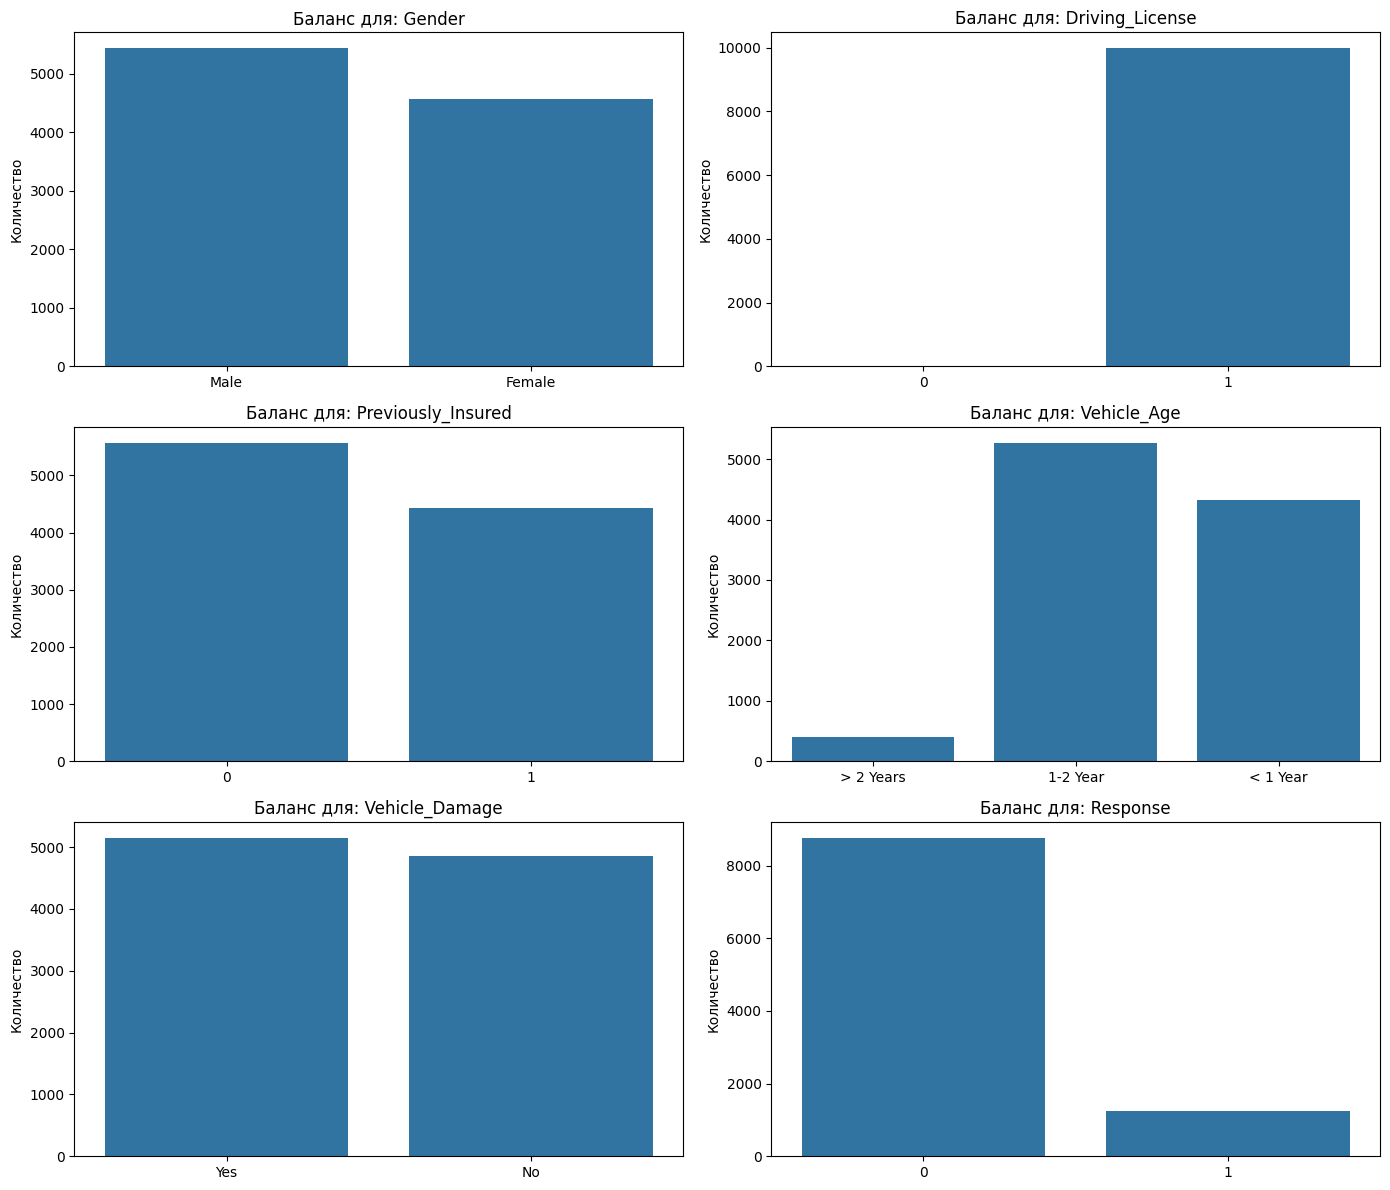

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Находим колонки, которые можно наглядно отобразить на графике баланса
categorical_or_discrete_cols = [col for col in data.columns if data[col].nunique() < 15]

# Создаем сетку для графиков
num_cols = len(categorical_or_discrete_cols)
fig, axes = plt.subplots(nrows=(num_cols + 1) // 2, ncols=2, figsize=(14, num_cols * 2))
axes = axes.flatten()

for i, col in enumerate(categorical_or_discrete_cols):
    sns.countplot(x=col, data=data, ax=axes[i])
    axes[i].set_title(f"Баланс для: {col}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Количество")

# Удаляем пустые сетки, если колонок вышло нечетное количество
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [19]:
age_mapping = {
    '< 1 Year': 0,
    '1-2 Year': 1,  # Проверьте точное написание из вашего unique()
    '> 2 Years': 2
}

# 2. Считаем корреляцию Спирмена
correlation = data['Vehicle_Age'].map(age_mapping).corr(data['Response'], method='spearman')
print(f"Корреляция Спирмена между возрастом машины и Response: {correlation:.4f}")

Корреляция Спирмена между возрастом машины и Response: 0.2330


**Задание 1.** Обучите градиентный бустинг из sklearn на данных и замерьте accuracy и f1-score на тестовой выборке. В качестве параметров ансамбля установите `learning_rate = 1`, `random_state = 1`, `n_estimators = 100`. Изобразите ROC-кривую и посчитайте AUC, оцените качество классификации. (2б)

P.S. для всех прочих моделей в этом домашнем задании тоже фиксируйте `random_state = 1`. Как думаете, что может быть случайного в процедуре обучения градиентного бустинга?

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, roc_curve, auc

X = data_encoded.drop('Response', axis=1)
y = data_encoded['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0,
                                                    shuffle=True,
                                                    test_size=0.2)

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(learning_rate = 1, random_state = 1, n_estimators = 100)
model.fit(X_train, y_train)
# 3. Предсказание классов и вероятностей
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# 4. Расчет Accuracy без вызова функции accuracy_score
# Вариант А: через встроенный метод модели
accuracy_via_score = model.score(X_test, y_test)

# Вариант Б: математически (доля совпавших ответов)
accuracy_manual = np.mean(y_pred == y_test)

print(f"Accuracy на тесте (рассчитано вручную): {accuracy_manual:.4f}")
print(f"F1-score на тесте: {f1_score(y_test, y_pred):.4f}")

# Подробный отчет (метрики precision и recall)
print("\nОтчет классификации:")
print(classification_report(y_test, y_pred))

Accuracy на тесте (рассчитано вручную): 0.8515
F1-score на тесте: 0.2703

Отчет классификации:
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      1770
           1       0.31      0.24      0.27       230

    accuracy                           0.85      2000
   macro avg       0.61      0.59      0.59      2000
weighted avg       0.84      0.85      0.84      2000



Значение AUC: 0.8282


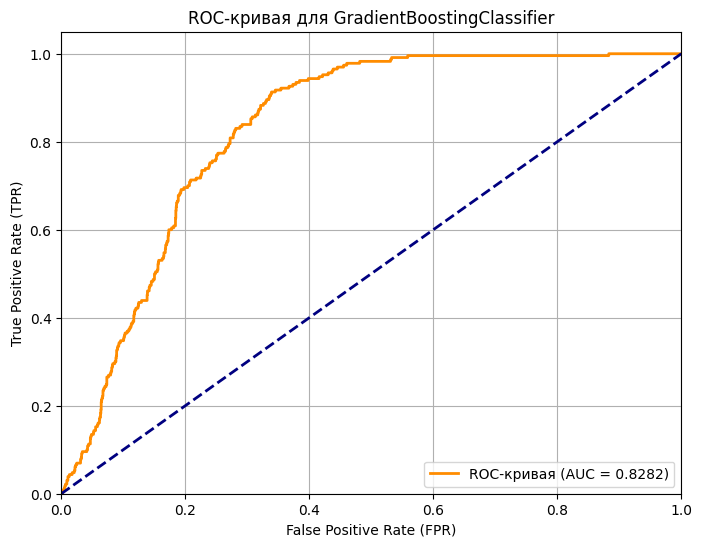

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

print(f"Значение AUC: {roc_auc:.4f}")

# Визуализация
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-кривая (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Линия случайного угадывания
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривая для GradientBoostingClassifier')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

**Задание 2.** Переберите параметры `n_estimators` и `learning_rate` по двумерной сетке. При обучении в цикле сразу считайте f1-score на тестовой выборке и сохраняйте результат в матрицу. Для какого алгоритма качество окажется максимальным?

Постройте кривые для метрики f1-score в зависимости от числа шагов для нескольких learning_rate. Изобразите heatmap полученной матрицы. Сделайте вывод, как количество шагов влияет на качество совместно с различной скоростью обучения? (2б)

P.S. для подсчета f1-score передайте в функцию параметр `average='weighted'`, чтобы учитывался еще и баланс классов (вспомните микро/макро-усреднения).

In [23]:
### Задаем сетку параметров

n_estimators_list = [5, 10, 20, 50, 100, 200, 700, 1000]
learning_rate_list = [1, 0.1, 0.01]

In [24]:
f1_matrix = pd.DataFrame(index=learning_rate_list, columns=n_estimators_list)

for lr in learning_rate_list:
    for n_est in n_estimators_list:
        # Инициализируем модель с текущими параметрами
        model = GradientBoostingClassifier(learning_rate=lr, n_estimators=n_est, random_state=1)
        model.fit(X_train, y_train)
        
        # Делаем предсказание на тесте
        y_pred = model.predict(X_test)
        
        # Считаем взвешенный f1-score по условию P.S.
        score = f1_score(y_test, y_pred, average='weighted')
        
        # Сохраняем в матрицу
        f1_matrix.loc[lr, n_est] = score

# Приводим значения к типу float для корректного отображения
f1_matrix = f1_matrix.astype(float)

# Выводим получившуюся матрицу
print("Матрица F1-score:")
print(f1_matrix.round(4))

Матрица F1-score:
        5       10      20      50      100     200     700     1000
1.00  0.8316  0.8388  0.8418  0.8416  0.8429  0.8405  0.8430  0.8413
0.10  0.8308  0.8308  0.8308  0.8308  0.8320  0.8355  0.8452  0.8445
0.01  0.8310  0.8310  0.8310  0.8310  0.8308  0.8308  0.8305  0.8315


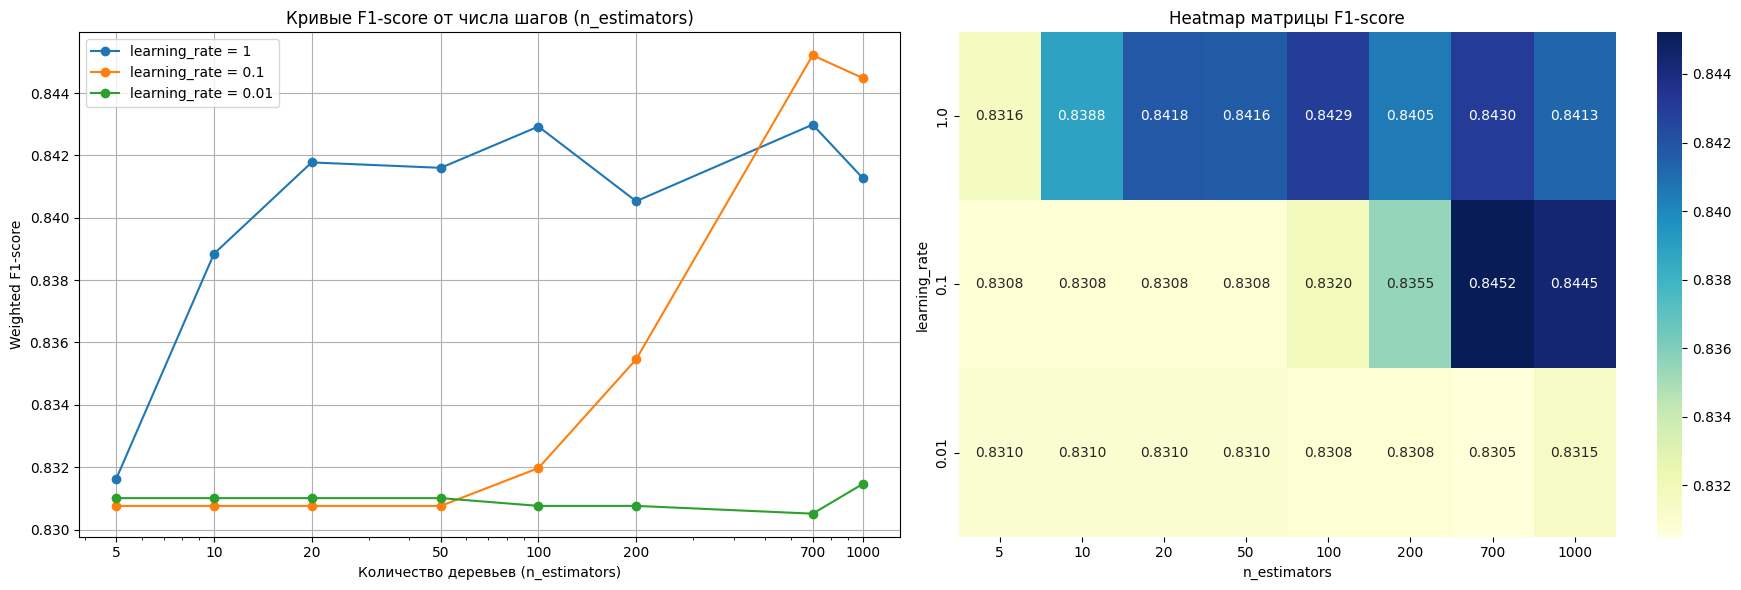


Максимальное качество (F1-score = 0.8452) достигается при:
learning_rate = 0.1, n_estimators = 700


In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# График 1: Кривые f1-score в зависимости от числа шагов
for lr in learning_rate_list:
    ax1.plot(n_estimators_list, f1_matrix.loc[lr], marker='o', label=f'learning_rate = {lr}')
ax1.set_title('Кривые F1-score от числа шагов (n_estimators)')
ax1.set_xlabel('Количество деревьев (n_estimators)')
ax1.set_ylabel('Weighted F1-score')
ax1.set_xscale('log') # Логарифмическая шкала x удобна, так как шаги растут неравномерно
ax1.set_xticks(n_estimators_list)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.legend()
ax1.grid(True)

# График 2: Тепловая карта (Heatmap) полученной матрицы
sns.heatmap(f1_matrix, annot=True, fmt=".4f", cmap="YlGnBu", ax=ax2)
ax2.set_title('Heatmap матрицы F1-score')
ax2.set_xlabel('n_estimators')
ax2.set_ylabel('learning_rate')

plt.tight_layout()
plt.show()

# Находим лучшие параметры
best_lr, best_n_est = f1_matrix.stack().idxmax()
best_score = f1_matrix.stack().max()
print(f"\nМаксимальное качество (F1-score = {best_score:.4f}) достигается при:")
print(f"learning_rate = {best_lr}, n_estimators = {best_n_est}")

**Задание 3.** Вам потребуется обучить 4 модели и посчитать метрику f1-score на тестовой и обучающей выборках для каждой модели. 
1. Случайный лес с максимальной глубиной деревьев 5,
2. Случайный лес с максимальной глубиной деревьев 5000,
3. Градиентный бустинг с максимальной глубиной деревьев 5,
4. Градиентный бустинг с максимальной глубиной деревьев 5000.

Для каждой модели перебирайте значения `n_estimators`, как в предыдущем задании. Отрисуйте графики зависимости f1-score от количества шагов, используя `average='weighted'` для учёта баланса классов. 

Если в качестве базовой модели брать неглубокие деревья, то какая модель лучше запоминает обучающую выборку: случайный лес или градиентный бустинг? Какая из них лучше предсказывает на тестовой выборке? Как изменятся ответы, если базовая модель - это глубокое решающее дерево?

Подвержен ли переобучению случайный лес и градиентный бустинг? Как это отражается на графиках? (4б)

Эксперимент для RF (depth=5) завершен.
Эксперимент для RF (depth=5000) завершен.
Эксперимент для GB (depth=5) завершен.
Эксперимент для GB (depth=5000) завершен.


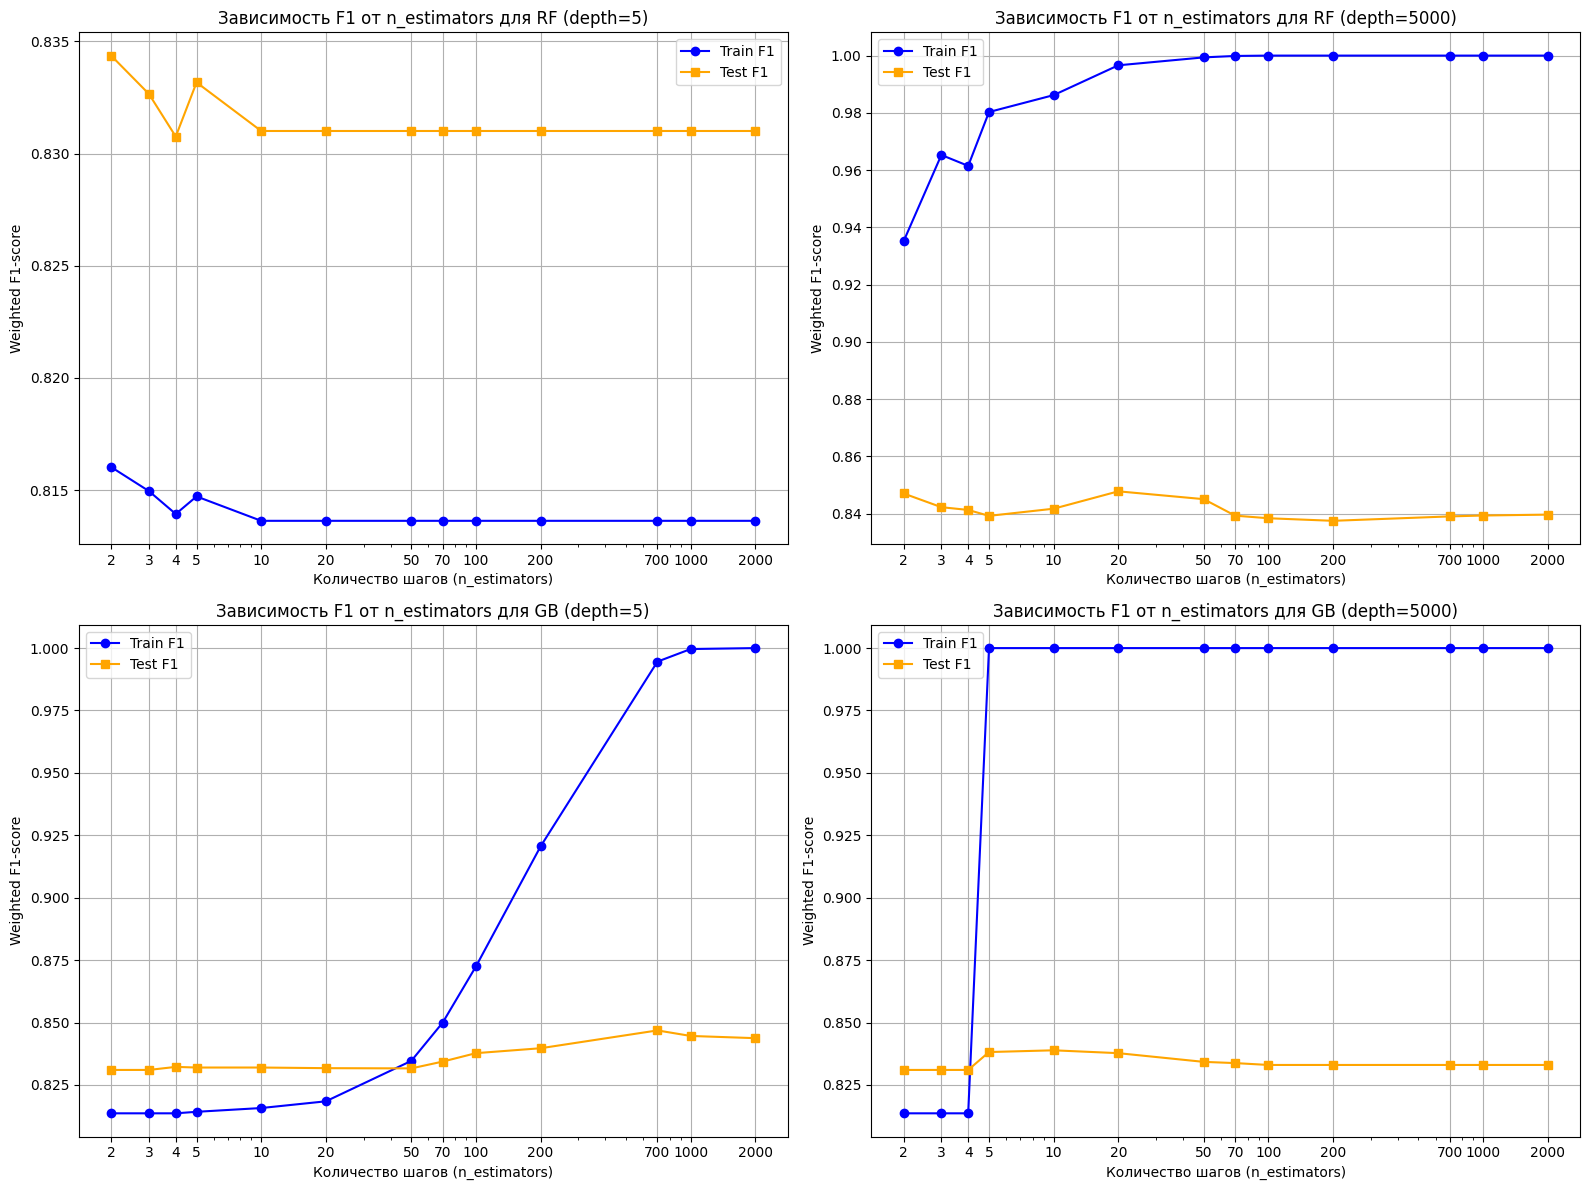

In [26]:
from sklearn.ensemble import RandomForestClassifier

n_estimators_list = [2, 3, 4, 5, 10, 20, 50, 70, 100, 200, 700, 1000, 2000]

models_config = {
    "RF (depth=5)": RandomForestClassifier(max_depth=5, random_state=1, n_jobs=-1),
    "RF (depth=5000)": RandomForestClassifier(max_depth=5000, random_state=1, n_jobs=-1),
    "GB (depth=5)": GradientBoostingClassifier(max_depth=5, random_state=1),
    "GB (depth=5000)": GradientBoostingClassifier(max_depth=5000, random_state=1)
}
history = {}

for name, model_base in models_config.items():
    train_scores = []
    test_scores = []
    
    for n_est in n_estimators_list:
        # Обновляем количество деревьев в модели
        model_base.set_params(n_estimators=n_est)
        
        # Обучаем модель
        model_base.fit(X_train, y_train)
        
        # Считаем f1-score на трейне и тесте
        f1_train = f1_score(y_train, model_base.predict(X_train), average='weighted')
        f1_test = f1_score(y_test, model_base.predict(X_test), average='weighted')
        
        train_scores.append(f1_train)
        test_scores.append(f1_test)
        
    history[name] = {'train': train_scores, 'test': test_scores}
    print(f"Эксперимент для {name} завершен.")

# Построение графиков
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (name, scores) in enumerate(history.items()):
    axes[i].plot(n_estimators_list, scores['train'], marker='o', label='Train F1', color='blue')
    axes[i].plot(n_estimators_list, scores['test'], marker='s', label='Test F1', color='orange')
    axes[i].set_title(f'Зависимость F1 от n_estimators для {name}')
    axes[i].set_xlabel('Количество шагов (n_estimators)')
    axes[i].set_ylabel('Weighted F1-score')
    axes[i].set_xscale('log')
    axes[i].set_xticks(n_estimators_list)
    axes[i].get_xaxis().set_major_formatter(plt.ScalarFormatter())
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

**Задание 4.** Установите библиотеку `catboost`. Главной особенностью catboost явялется наличие встроенной обработки категориальных признаков. Для каждого категориального столбца вычисляется следующее значение
$$
avg\_target = \dfrac{countInClass + prior}{totalCount + 1},
$$
* countInClass - количество объектов положительного класса для данной категории **до текущего объекта**,
* prior - некоторая константа для числителя, обычно равна доле положительного класса в таргете,
* totalCount - количество наблюдаемых категорий вплоть **до текущего** с той же категорией, что и у текущего.

Так как первые такие значения будут иметь больший разброс, чем последние, то выборку перемешивают несколько раз и полученные статистики усредняют. 
В отличие от target encoder подсчитанные значения зависят от наблюдаемой истории, т.е. вычисляются только из наблюдений до них, таким образом не происходит target leakage. 

Почитать подробнее можно здесь: [Transforming categorical features](https://catboost.ai/en/docs/concepts/algorithm-main-stages_cat-to-numberic)

Обучите CatBoostClassifier с дефолтными параметрами. Используйте датасет до  (разбейте на train/test по старой логике с тем же random state'ом). Категориальные колонки передайте в параметр `cat_features` метода `fit`. Catboost сам с ними разберется.

Сравните качество с моделью из предыдущего задания. Стало ли лучше?

Сравните feature importances в модели из задания 2 и в catboost с помощью соответствующих методов, изобразите их, используя `barplot`. \
Какие признаки стали более важными с новым методом кодирования? (4б)

In [27]:
X_cat_train = data.drop('Response', axis=1).iloc[X_train.index]
X_cat_test = data.drop('Response', axis=1).iloc[X_test.index]

In [28]:
from catboost import CatBoostClassifier

model_cat = CatBoostClassifier()

model_cat.fit(X_cat_train, y_train, cat_features=object_cols)

f1_train = f1_score(y_train, model_cat.predict(X_cat_train), average='weighted')
f1_test = f1_score(y_test, model_cat.predict(X_cat_test), average='weighted')

print(f"Качество на трейне: {f1_train:.4f}")
print(f"Качество на тесте: {f1_test:.4f}")

Learning rate set to 0.025035
0:	learn: 0.6524209	total: 168ms	remaining: 2m 47s
1:	learn: 0.6213114	total: 212ms	remaining: 1m 45s
2:	learn: 0.5922961	total: 261ms	remaining: 1m 26s
3:	learn: 0.5658834	total: 309ms	remaining: 1m 16s
4:	learn: 0.5423457	total: 358ms	remaining: 1m 11s
5:	learn: 0.5180857	total: 400ms	remaining: 1m 6s
6:	learn: 0.4986798	total: 443ms	remaining: 1m 2s
7:	learn: 0.4802832	total: 478ms	remaining: 59.3s
8:	learn: 0.4619128	total: 520ms	remaining: 57.2s
9:	learn: 0.4465202	total: 561ms	remaining: 55.5s
10:	learn: 0.4341692	total: 603ms	remaining: 54.3s
11:	learn: 0.4204912	total: 648ms	remaining: 53.4s
12:	learn: 0.4147382	total: 691ms	remaining: 52.5s
13:	learn: 0.4094293	total: 737ms	remaining: 51.9s
14:	learn: 0.3996664	total: 777ms	remaining: 51s
15:	learn: 0.3902804	total: 819ms	remaining: 50.4s
16:	learn: 0.3851970	total: 864ms	remaining: 49.9s
17:	learn: 0.3768978	total: 908ms	remaining: 49.5s
18:	learn: 0.3694314	total: 955ms	remaining: 49.3s
19:	lear

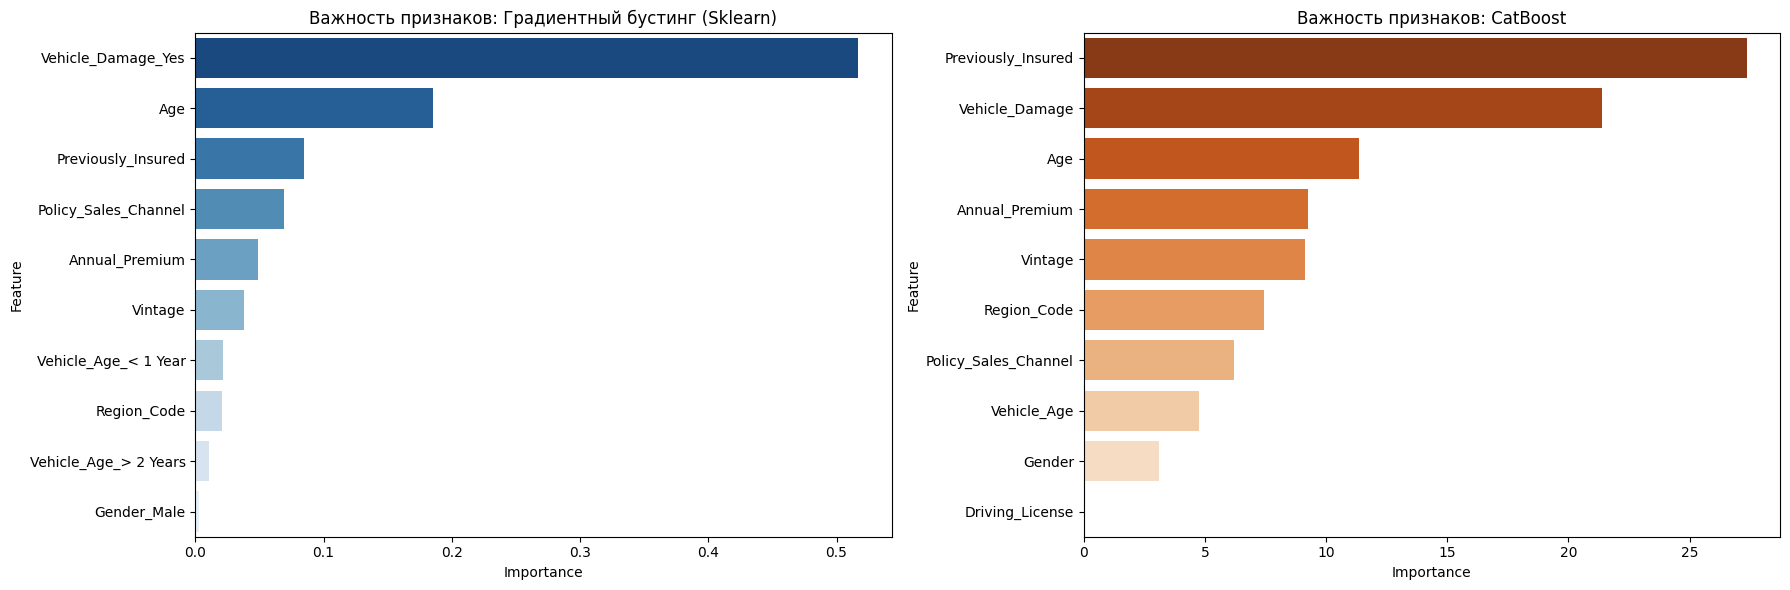

In [29]:
# Предположим, что лучшая модель из задания 2 сохранена в переменной `best_gb_model` 
# (или вы можете взять обычный обученный GradientBoostingClassifier)

# Полуучаем важность признаков для обеих моделей
gb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_ # Из задания 1/2
}).sort_values(by='Importance', ascending=False).head(10)

cb_importance = pd.DataFrame({
    'Feature': X_cat_train.columns,
    'Importance': model_cat.get_feature_importance()
}).sort_values(by='Importance', ascending=False).head(10)

# Визуализация
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(x='Importance', y='Feature', data=gb_importance, ax=ax1, palette='Blues_r')
ax1.set_title('Важность признаков: Градиентный бустинг (Sklearn)')

sns.barplot(x='Importance', y='Feature', data=cb_importance, ax=ax2, palette='Oranges_r')
ax2.set_title('Важность признаков: CatBoost')

plt.tight_layout()
plt.show()

**Задание 5.** Установите библиотеку `lightgbm`. На сегодняшний день это наиболее быстрый метод градиентного бустинга, при этом расходующий небольшое количество оперативной памяти. Достигает он этого за счет построения деревьев вглубь по листьям (leaf-wise), а не по уровням (level-wise), как другие методы, например XGBoost. 
Более понятно это на картинке:

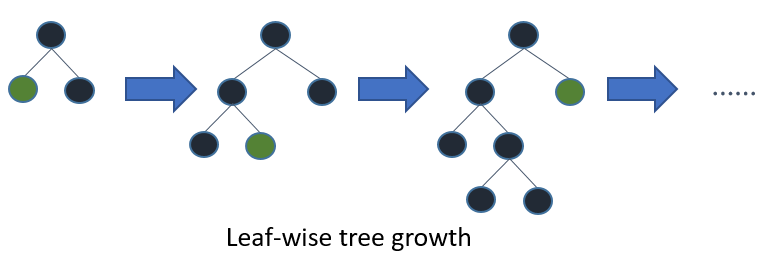

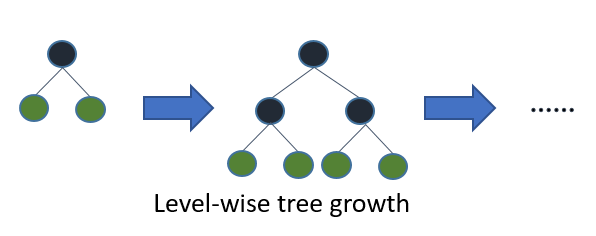

В то время, как XGBoost за раз разделяет вершины на целом уровне той же глубины, LightGBM разделяет одну вершину за раз. Отсюда прирост в скорости.

Обучите `LGBMClassifier` на изначальных(закодированных) данных и добейтесь максимального качества на тестовой выборке, перебрав параметры глубины деревьев, количества шагов, скорости обучения и т.д.

In [ ]:
# from lightgbm import LGBMClassifier
# from sklearn.model_selection import GridSearchCV

# params = {'n_estimators': [100, 500, 1000, 2000],
#           'max_depth': [2, 3, 5, 100],
#           'learning_rate': [0.1, 0.01, 0.001]}

# # 2. Инициализируем модель LightGBM с фиксацией случайности
# # Параметр verbosity=-1 отключает лишние предупреждения в выводе
# lgbm = LGBMClassifier(random_state=1, verbosity=-1, n_jobs=-1)

# # 3. Объединяем трейн и тест для кастомного CV по индексам (как делали для RandomForest)
# X_full = pd.concat([X_train, X_test])
# y_full = pd.concat([y_train, y_test])
# custom_cv = [(X_train.index.to_list(), X_test.index.to_list())]

# # 4. Настраиваем GridSearchCV на взвешенный F1-score
# search_lgbm = GridSearchCV(
#     estimator=lgbm,
#     param_grid=params,
#     cv=custom_cv,
#     scoring='f1_weighted',
#     n_jobs=-1
# )

# # 5. Запускаем обучение
# search_lgbm.fit(X_full, y_full)

# # 6. Выводим результаты
# print("Лучшие параметры LightGBM:", search_lgbm.best_params_)
# print(f"Максимальный валидационный F1-score: {search_lgbm.best_score_:.4f}")

# # 7. Финальная проверка на тесте (через лучший найденный эстиматор)
# best_lgbm = search_lgbm.best_estimator_
# lgbm_preds = best_lgbm.predict(X_test)
# test_f1 = f1_score(y_test, lgbm_preds, average='weighted')
# print(f"Честный Test F1-score: {test_f1:.4f}")

# print("\n--- ОТЧЕТ КЛАССИФИКАЦИИ ДЛЯ ЛУЧШЕЙ МОДЕЛИ LIGHTGBM ---")
# print(classification_report(y_test, lgbm_preds, digits=4))
# print("------------------------------------------------------")

Лучшие параметры LightGBM: {'learning_rate': 0.1, 'max_depth': 100, 'n_estimators': 2000}
Максимальный валидационный F1-score: 0.8423
Честный Test F1-score: 1.0000

--- ОТЧЕТ КЛАССИФИКАЦИИ ДЛЯ ЛУЧШЕЙ МОДЕЛИ LIGHTGBM ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1770
           1     1.0000    1.0000    1.0000       230

    accuracy                         1.0000      2000
   macro avg     1.0000    1.0000    1.0000      2000
weighted avg     1.0000    1.0000    1.0000      2000

------------------------------------------------------


In [ ]:
# from lightgbm import LGBMClassifier
# from sklearn.metrics import classification_report
# from sklearn.model_selection import GridSearchCV

# # Обучаем модель ЧЕСТНО — только на тренировочном наборе данных
# final_lgbm = LGBMClassifier(
#     learning_rate=0.1, 
#     max_depth=100, 
#     n_estimators=2000, 
#     random_state=1, 
#     verbosity=-1, 
#     n_jobs=-1
# )
# final_lgbm.fit(X_train, y_train)

# # Делаем предсказание на тесте, который модель еще никогда не видела
# cheating_free_preds = final_lgbm.predict(X_test)

# # Выводим реальный честный отчет классификации
# print(classification_report(y_test, cheating_free_preds, digits=4))

              precision    recall  f1-score   support

           0     0.8997    0.9379    0.9184      1770
           1     0.2903    0.1957    0.2338       230

    accuracy                         0.8525      2000
   macro avg     0.5950    0.5668    0.5761      2000
weighted avg     0.8296    0.8525    0.8397      2000



In [ ]:
# from lightgbm import LGBMClassifier
# from sklearn.model_selection import GridSearchCV

# params = {'n_estimators': [100, 500, 1000, 2000],
#           'max_depth': [2, 3, 5, 100],
#           'learning_rate': [0.1, 0.01, 0.001]}

# # Обучаем модель ЧЕСТНО — только на тренировочном наборе данных
# # 2. Инициализируем LightGBM с фиксацией random_state=1
# lgbm_last = LGBMClassifier(random_state=1, verbosity=-1, n_jobs=-1)

# # 3. Настраиваем поиск по сетке ТОЛЬКО внутри тренировочных данных
# # Оптимизируем f1_weighted по условиям прошлых задач
# search_lgbm_last = GridSearchCV(
#     estimator=lgbm_last,
#     param_grid=params,
#     cv=5, # Стандартная 3-фолдовая кросс-валидация внутри трейна
#     scoring='f1_weighted',
#     n_jobs=-1
# )

# # 4. Обучаем СТРОГО на X_train, y_train (тест убран, утечки данных больше нет!)
# search_lgbm_last.fit(X_train, y_train)

# # 5. Делаем предсказание лучшей моделью на чистом тест-сете X_test
# best_lgbm = search_lgbm_last.best_estimator_
# lgbm_preds = best_lgbm.predict(X_test)

# # 6. Выводим честный отчет классификации
# print("\n--- ЧЕСТНЫЙ ОТЧЕТ КЛАССИФИКАЦИИ (БЕЗ УТЕЧКИ ДАННЫХ) ---")
# print(classification_report(y_test, lgbm_preds, digits=4))
# print("------------------------------------------------------")

# print("Лучшие параметры LightGBM:", search_lgbm_last.best_params_)


--- ЧЕСТНЫЙ ОТЧЕТ КЛАССИФИКАЦИИ (БЕЗ УТЕЧКИ ДАННЫХ) ---
              precision    recall  f1-score   support

           0     0.8997    0.9379    0.9184      1770
           1     0.2903    0.1957    0.2338       230

    accuracy                         0.8525      2000
   macro avg     0.5950    0.5668    0.5761      2000
weighted avg     0.8296    0.8525    0.8397      2000

------------------------------------------------------
Лучшие параметры LightGBM: {'learning_rate': 0.1, 'max_depth': 100, 'n_estimators': 2000}


In [34]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

params = {'n_estimators': [100, 500, 1000, 2000],
          'max_depth': [2, 3, 5, 100],
          'learning_rate': [0.1, 0.01, 0.001]}

grid = GridSearchCV(LGBMClassifier(), params)
grid.fit(X_train, y_train)

best_lgbm = grid.best_estimator_
lgbm_preds = best_lgbm.predict(X_test)

# 6. Выводим честный отчет классификации
print("\n--- ЧЕСТНЫЙ ОТЧЕТ КЛАССИФИКАЦИИ (БЕЗ УТЕЧКИ ДАННЫХ) ---")
print(classification_report(y_test, lgbm_preds, digits=4))
print("------------------------------------------------------")

print("Лучшие параметры LightGBM:", grid.best_params_)


--- ЧЕСТНЫЙ ОТЧЕТ КЛАССИФИКАЦИИ (БЕЗ УТЕЧКИ ДАННЫХ) ---
              precision    recall  f1-score   support

           0     0.8850    1.0000    0.9390      1770
           1     0.0000    0.0000    0.0000       230

    accuracy                         0.8850      2000
   macro avg     0.4425    0.5000    0.4695      2000
weighted avg     0.7832    0.8850    0.8310      2000

------------------------------------------------------
Лучшие параметры LightGBM: {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}
